---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 1"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 3. Каскади зі спільним емітером, спільним витоком і спільним колектором</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>1.13. Каскад за схемою зі спільним емітером. Основні параметри і співвідношення. Кола зміщення та стабілізація</li>
  <li>1.14. Каскад за схемою зі спільним витоком. Основні параметри і співвідношення. Кола зміщення та стабілізація</li>
  <li>1.15. Каскад за схемою зі спільним колектором. Основні параметри і співвідношення. Кола зміщення та стабілізація</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 3 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Вступ: транзистор як підсилювальний елемент](#intro)
* [Каскад зі спільним емітером (СЕ)](#ce-stage)
    * [🔬 Інтерактивно: стабільність робочої точки при розкиді β (PySpice)](#bias-interactive)
    * [🔬 Інтерактивно: АЧХ каскаду СЕ і роль конденсатора $C_е$ (PySpice)](#ce-ac-interactive)
* [Каскад зі спільним витоком (СВ)](#cs-stage)
    * [🔬 Інтерактивно: режим спокою і підсилення каскаду СВ (PySpice)](#cs-interactive)
* [Каскад зі спільним колектором (емітерний повторювач)](#cc-stage)
    * [🔬 Інтерактивно: емітерний повторювач: обмеження від'ємної півхвилі (PySpice)](#cc-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Вступ: транзистор як підсилювальний елемент <a class="anchor" id="intro"></a>

Транзистор має три виводи, тому в підсилювальному каскаді один з них є **спільним** для вхідного і вихідного кіл. Для біполярного транзистора (БТ) це схеми зі спільним емітером (СЕ), спільною базою (СБ) і спільним колектором (СК); для польового (ПТ) — зі спільним витоком (СВ), спільним затвором (СЗ) і спільним стоком (СС).

**Малосигнальні параметри БТ** (у робочій точці зі струмом колектора $I_{к0}$):
- крутизна $g_m = \dfrac{I_{к0}}{\varphi_т}$, де $\varphi_т = kT/q \approx 26$ мВ при 300 К;
- коефіцієнт передачі струму бази $\beta = h_{21е}$ (50…500);
- вхідний опір $h_{11е} = r_б + (1+\beta)\,r_е \approx \beta/g_m$, де $r_е = \varphi_т/I_{е0}$ — диференціальний опір емітерного переходу;
- вихідна провідність $h_{22е} = 1/r_к$ (ефект Ерлі, $r_к = U_A/I_{к0}$).

**Малосигнальні параметри ПТ:** крутизна $S = g_m = \partial I_с/\partial U_{зв}$; для ПТ з керувальним p-n переходом (квадратична модель $I_с = I_{с.поч}(1 - U_{зв}/U_{відс})^2$)
$$S = \frac{2I_{с.поч}}{|U_{відс}|}\left(1 - \frac{U_{зв}}{U_{відс}}\right) = \frac{2\sqrt{I_{с.поч}I_с}}{|U_{відс}|};$$
вхідний опір затвора — $10^9\ldots10^{14}$ Ом; диференціальний опір каналу $r_с$.

**Робоча точка (точка спокою)** задається колами зміщення так, щоб транзистор працював в активному режимі посередині лінійної ділянки, а **стабілізація** — щоб ця точка не «пливла» через розкид параметрів і температуру. Для БТ головні дестабілізувальні чинники — зростання $\beta$ і зворотного струму $I_{кб0}$ з температурою та зменшення $U_{бе}$ на ≈ 2 мВ/°C.

---

## Каскад зі спільним емітером (СЕ) <a class="anchor" id="ce-stage"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.13</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати призначення кожного елемента каскаду СЕ
> - Розраховувати режим спокою, $K_u$, $R_{вх}$, $R_{вих}$ каскаду СЕ
> - Порівнювати схеми зміщення фіксованим струмом бази, колекторної та емітерної стабілізації
> - Розраховувати коефіцієнт нестабільності $S$

</div>

Каскад СЕ — найпоширеніший підсилювальний каскад: він **підсилює і напругу, і струм** (найбільше підсилення за потужністю), але **інвертує** сигнал (фазовий зсув $180°$).

**Призначення елементів:** $R_{б1}, R_{б2}$ — дільник, що задає напругу бази (зміщення); $R_к$ — колекторне навантаження, на якому виділяється змінна напруга; $R_е$ — емітерна стабілізація (послідовний НЗЗ за струмом за постійним струмом); $C_е$ — шунтує $R_е$ за змінним струмом, щоб НЗЗ не зменшував підсилення; $C_1, C_2$ — розділювальні конденсатори (не пропускають постійну складову від джерела і в навантаження).

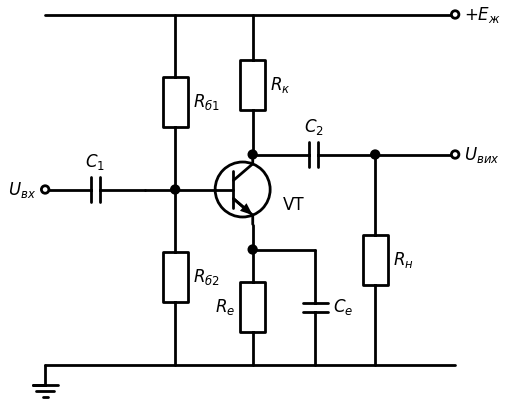

In [2]:
# Каскад СЕ з емітерною стабілізацією (дільник у колі бази + R_е, C_е)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (8.2, 7)); d += elm.Dot(open=True).at((8.2, 7)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8.2, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 3.5)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 3.5)).to((2, 3.5)).label('$C_1$')
        d += W((2, 3.5), (3.4, 3.5)); d += elm.Dot().at((2.6, 3.5))
        d += elm.Resistor().at((2.6, 7)).to((2.6, 3.5)).label('$R_{б1}$', loc='bottom')
        d += elm.Resistor().at((2.6, 3.5)).to((2.6, 0)).label('$R_{б2}$', loc='bottom')
        d += elm.BjtNpn(circle=True).theta(0).at((3.4, 3.5)).anchor('base').label('VT', loc='right', ofst=(0.25, -0.3))
        d += elm.Resistor().at((4.15, 7)).to((4.15, 4.2)).label('$R_к$', loc='bottom')
        d += W((4.15, 2.8), (4.15, 2.3)); d += elm.Dot().at((4.15, 2.3))
        d += elm.Resistor().at((4.15, 2.3)).to((4.15, 0)).label('$R_е$', loc='top')
        d += W((4.15, 2.3), (5.4, 2.3)); d += elm.Capacitor().at((5.4, 2.3)).to((5.4, 0)).label('$C_е$', loc='bottom')
        d += elm.Dot().at((4.15, 4.2))
        d += elm.Capacitor().at((4.15, 4.2)).to((6.6, 4.2)).label('$C_2$')
        d += elm.Dot().at((6.6, 4.2)); d += W((6.6, 4.2), (8.2, 4.2)); d += elm.Dot(open=True).at((8.2, 4.2)).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((6.6, 4.2)).to((6.6, 0)).label('$R_н$', loc='bottom')

### Режим спокою

Напруга і еквівалентний опір дільника: $U_{б0} = E_ж\dfrac{R_{б2}}{R_{б1}+R_{б2}}$, $\;R_б = R_{б1}\parallel R_{б2}$. Тоді
$$I_{е0} = \frac{U_{б0} - U_{бе0}}{R_е + R_б/(1+\beta)} \approx \frac{U_{б0} - 0{,}65\text{ В}}{R_е},\qquad U_{ке0} = E_ж - I_{к0}(R_к + R_е).$$
Якщо струм дільника значно більший за струм бази ($R_б \ll \beta R_е$), струм спокою **практично не залежить від $\beta$** — у цьому суть емітерної стабілізації. Для максимального неспотвореного розмаху вибирають $U_{ке0} \approx (E_ж - I_{к0}R_е)/2$.

### Параметри для змінного сигналу (середні частоти, $C_е$ шунтує $R_е$)

$$K_u = -\frac{\beta\,(R_к\parallel R_н)}{h_{11е}} = -g_m\,(R_к\parallel R_н),\qquad R_{вх} = R_б\parallel h_{11е},\qquad R_{вих} \approx R_к\parallel r_к \approx R_к .$$
$$K_i = \beta\cdot\frac{R_б}{R_б + h_{11е}}\cdot\frac{R_к}{R_к + R_н}.$$
Якщо $R_е$ **не шунтовано** (є місцевий послідовний НЗЗ за струмом):
$$K_u \approx -\frac{R_к\parallel R_н}{r_е + R_е} \approx -\frac{R_к\parallel R_н}{R_е},\qquad R_{вх.тр} = h_{11е} + (1+\beta)R_е .$$
Підсилення зменшується, зате стає стабільним (визначається відношенням резисторів), лінійнішим, а вхідний опір зростає. Часто $R_е$ розділяють на дві частини і шунтують лише одну — як у темі 2.

### Схеми зміщення та стабілізації

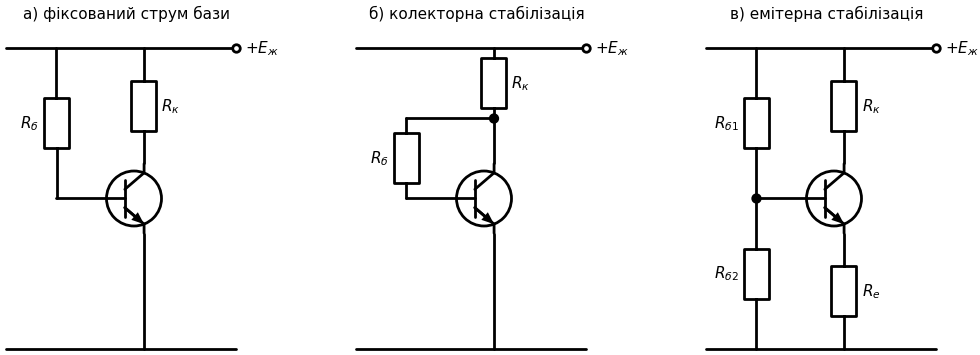

In [3]:
# Три способи зміщення каскаду СЕ
if SCHEMDRAW_AVAILABLE:
    def bias(d, ox, kind, title):
        W = lambda p1, p2: elm.Line().at((ox + p1[0], p1[1])).to((ox + p2[0], p2[1]))
        d += W((0, 6), (4.6, 6)); d += elm.Label().at((ox + 2.3, 6.6)).label(title, fontsize=11)
        d += W((0, 0), (4.6, 0)); d += elm.Dot(open=True).at((ox + 4.6, 6)).label('$+E_ж$', loc='right')
        d += elm.BjtNpn(circle=True).theta(0).at((ox + 2.0, 3)).anchor('base')
        d += elm.Resistor().at((ox + 2.75, 6)).to((ox + 2.75, 4.6 if kind == 'collector' else 3.7)).label('$R_к$', loc='bottom')
        if kind == 'fixed':
            d += elm.Resistor().at((ox + 1.0, 6)).to((ox + 1.0, 3)).label('$R_б$', loc='top'); d += W((1.0, 3), (2.0, 3))
            d += W((2.75, 2.3), (2.75, 0))
        elif kind == 'collector':
            d += W((2.75, 4.6), (2.75, 3.7)); d += elm.Dot().at((ox + 2.75, 4.6))
            d += W((2.75, 4.6), (1.0, 4.6))
            d += elm.Resistor().at((ox + 1.0, 4.6)).to((ox + 1.0, 3)).label('$R_б$', loc='top'); d += W((1.0, 3), (2.0, 3))
            d += W((2.75, 2.3), (2.75, 0))
        else:
            d += elm.Resistor().at((ox + 1.0, 6)).to((ox + 1.0, 3)).label('$R_{б1}$', loc='top')
            d += elm.Resistor().at((ox + 1.0, 3)).to((ox + 1.0, 0)).label('$R_{б2}$', loc='top')
            d += W((1.0, 3), (2.0, 3)); d += elm.Dot().at((ox + 1.0, 3))
            d += elm.Resistor().at((ox + 2.75, 2.3)).to((ox + 2.75, 0)).label('$R_е$', loc='bottom')
    with schemdraw.Drawing(fontsize=11, unit=2) as d:
        bias(d, 0, 'fixed', 'а) фіксований струм бази')
        bias(d, 7, 'collector', 'б) колекторна стабілізація')
        bias(d, 14, 'emitter', 'в) емітерна стабілізація')

**а) Фіксований струм бази:** $I_{б0} = (E_ж - U_{бе})/R_б$, $\;I_{к0} = \beta I_{б0}$. Найпростіша, але **найгірша** схема: струм колектора прямо пропорційний $\beta$, яке має розкид у рази і зростає з температурою. Коефіцієнт нестабільності $S = 1 + \beta$.

**б) Колекторна стабілізація:** резистор $R_б$ підключено до колектора — це **паралельний НЗЗ за напругою**. Якщо $I_к$ зростає, напруга на колекторі падає, струм бази зменшується і компенсує зростання. $S \approx \dfrac{1+\beta}{1 + \beta R_к/(R_к + R_б)}$. Недолік — НЗЗ діє і на змінному сигналі, зменшуючи підсилення та вхідний опір (якщо не розділити $R_б$ на дві частини з конденсатором посередині).

**в) Емітерна стабілізація (дільник + $R_е$):** **послідовний НЗЗ за струмом**. Зростання $I_е$ збільшує напругу $I_еR_е$, отже зменшує $U_{бе} = U_{б0} - I_еR_е$ і закриває транзистор. Найкраща стабільність:
$$S = \frac{\Delta I_к}{\Delta I_{кб0}} = \frac{(1+\beta)(R_б + R_е)}{R_б + (1+\beta)R_е} \approx 1 + \frac{R_б}{R_е}\quad(\beta R_е \gg R_б).$$
На практиці вибирають $S = 2\ldots5$ ($R_б \approx (2\ldots5) R_е$), $U_{Rе} \approx (0{,}1\ldots0{,}2)E_ж$, струм дільника $I_д \approx (5\ldots10)I_{б0}$.

Додатково для температурної компенсації в дільник можуть вмикати діод або терморезистор (зменшення $U_{бе}$ з температурою компенсується зменшенням напруги на діоді).

---
### 🔬 Інтерактивно: стабільність робочої точки при розкиді β (PySpice) <a class="anchor" id="bias-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Дві схеми розраховано на однаковий струм спокою $I_{к0} \approx 1$ мА при $\beta = 150$, $E_ж = 12$ В, $R_к = 5{,}6$ кОм. Змінюйте $\beta$ транзистора (розкид у партії або нагрівання) і температуру. У схемі з фіксованим струмом бази робоча точка «з'їжджає» аж до насичення, а емітерна стабілізація утримує її майже незмінною.

</div>

In [4]:
# Порівняння схем зміщення: фіксований струм бази та дільник + R_е (модель NPN зі змінним β)
def bias_compare(beta=150.0, temp=25.0):
    def run(kind):
        c = Circuit('bias')
        c.model('QX', 'NPN', BF=beta, IS=1e-14, VAF=100)
        c.V('cc', 'vcc', c.gnd, 12)
        c.R('c', 'vcc', 'c', 5.6e3)
        if kind == 'fixed':
            c.R('b', 'vcc', 'b', 1.7e6)       # I_б0 ≈ (12 − 0,65)/1,7 МОм ≈ 6,7 мкА -> I_к0 ≈ 1 мА при β = 150
            c.BJT(1, 'c', 'b', c.gnd, model='QX')
        else:
            c.R('b1', 'vcc', 'b', 47e3); c.R('b2', 'b', c.gnd, 10e3); c.R('e', 'e', c.gnd, 1.33e3)
            c.BJT(1, 'c', 'b', 'e', model='QX')
        op = c.simulator(temperature=temp, nominal_temperature=25).operating_point()
        uc = float(np.array(op['c'])[0]); ic = (12 - uc) / 5.6e3
        ue = float(np.array(op['e'])[0]) if kind != 'fixed' else 0.0
        return ic * 1e3, uc - ue
    r = {k: run(k) for k in ('fixed', 'emitter')}
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    names = ['фіксований\nструм бази', 'дільник + $R_е$']
    a1.bar(names, [r['fixed'][0], r['emitter'][0]], color=['#F44336', '#4CAF50']); a1.axhline(1.0, color='k', ls='--', lw=1)
    a1.set_ylabel('$I_{к0}$, мА'); a1.set_ylim(0, 2.3); a1.set_title('Струм колектора спокою')
    a2.bar(names, [r['fixed'][1], r['emitter'][1]], color=['#F44336', '#4CAF50']); a2.set_ylim(0, 12)
    a2.set_ylabel('$U_{ке0}$, В'); a2.set_title('Напруга колектор–емітер')
    for ax, idx in ((a1, 0), (a2, 1)):
        for i, k in enumerate(('fixed', 'emitter')):
            ax.text(i, r[k][idx], f'{r[k][idx]:.2f}', ha='center', va='bottom')
    plt.tight_layout(); plt.show()
    if r['fixed'][1] < 0.3:
        print('⚠️ Схема з фіксованим струмом бази увійшла в насичення!')
    print(f"Фіксований струм бази: I_к0 = {r['fixed'][0]:.2f} мА;  дільник + R_е: I_к0 = {r['emitter'][0]:.2f} мА  "
          f"(S ≈ 1 + R_б/R_е = {1 + (47*10/57)/1.33:.1f})")

interact(bias_compare,
         beta=widgets.FloatSlider(min=50, max=400, step=10, value=150, description='β'),
         temp=widgets.FloatSlider(min=-40, max=100, step=5, value=25, description='T (°C)'));

interactive(children=(FloatSlider(value=150.0, description='β', max=400.0, min=50.0, step=10.0), FloatSlider(v…

---
### 🔬 Інтерактивно: АЧХ каскаду СЕ і роль конденсатора $C_е$ (PySpice) <a class="anchor" id="ce-ac-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Каскад СЕ на 2N3904 ($E_ж = 12$ В, $R_{б1} = 47$ кОм, $R_{б2} = 10$ кОм, $R_к = 4{,}7$ кОм, $R_е = 1$ кОм). Зменшуйте $C_е$: на низьких частотах опір конденсатора зростає, вмикається НЗЗ через $R_е$ і підсилення падає до $\approx R_к\parallel R_н / R_е$. Під графіком — порівняння з формулою $K_u = -g_m (R_к\parallel R_н)$.

</div>

In [5]:
# Каскад СЕ: AC-аналіз, вплив C_е і R_н
def ce_ac(Ce_uF=100.0, Rl_k=10.0):
    c = Circuit('CE amplifier')
    c.include(spice_model('2n3904.lib'))
    c.V('cc', 'vcc', c.gnd, 12)
    c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1)
    c.C(1, 'src', 'b', 10e-6); c.R('b1', 'vcc', 'b', 47e3); c.R('b2', 'b', c.gnd, 10e3)
    c.BJT(1, 'c', 'b', 'e', model='Q2N3904')
    c.R('c', 'vcc', 'c', 4.7e3); c.R('e', 'e', c.gnd, 1e3); c.C('e', 'e', c.gnd, Ce_uF * 1e-6)
    c.C(2, 'c', 'out', 10e-6); c.R('L', 'out', c.gnd, Rl_k * 1e3)
    op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
    ie = float(np.array(op['e'])[0]) / 1e3
    f, v = ac(c, 1, 1e8, 30)
    g = np.abs(v['out'])
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    a1.semilogx(f, db(g), color='#2196F3'); a1.set_ylabel('$K_u$, дБ'); a1.set_title(f'Каскад СЕ: $C_е$ = {Ce_uF:g} мкФ, $R_н$ = {Rl_k:g} кОм')
    Rp = 4.7e3 * Rl_k * 1e3 / (4.7e3 + Rl_k * 1e3)
    a1.axhline(db(Rp / 1e3), color='#FF9800', ls=':', label='$R_к\\parallel R_н / R_е$ (без $C_е$)'); a1.legend(loc='lower center')
    a2.semilogx(f, np.degrees(np.unwrap(np.angle(v['out']))), color='#FF9800'); a2.set_ylabel('φ, град'); a2.set_xlabel('Частота, Гц')
    plt.tight_layout(); plt.show()
    gm = ie / 0.02585
    print(f'Режим: I_е0 = {ie*1e3:.2f} мА, g_m = {gm*1e3:.1f} мА/В;  формула |K_u| = g_m·(R_к‖R_н) = {gm*Rp:.0f};  '
          f'PySpice (макс.): {g.max():.0f}')

interact(ce_ac,
         Ce_uF=widgets.FloatLogSlider(base=10, min=-1, max=3, step=0.1, value=100, description='Cе (мкФ)'),
         Rl_k=widgets.FloatLogSlider(base=10, min=0, max=2, step=0.1, value=10, description='Rн (кОм)'));

interactive(children=(FloatLogSlider(value=100.0, description='Cе (мкФ)', max=3.0, min=-1.0), FloatLogSlider(v…

---

## Каскад зі спільним витоком (СВ) <a class="anchor" id="cs-stage"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.14</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу каскаду СВ на польовому транзисторі
> - Розраховувати режим спокою з автоматичним зміщенням і за допомогою дільника
> - Розраховувати $K_u$, $R_{вх}$, $R_{вих}$ каскаду СВ та порівнювати його з каскадом СЕ

</div>

Каскад СВ — аналог каскаду СЕ на польовому транзисторі: **інвертує** сигнал і підсилює напругу. Його головна перевага — **дуже великий вхідний опір** (визначається резистором $R_з$, 1…10 МОм, бо струм затвора практично нульовий). Недолік — менше підсилення, ніж у СЕ, оскільки крутизна ПТ ($S \sim$ 1…10 мА/В) значно менша, ніж у БТ при тому самому струмі ($g_m = I_к/\varphi_т \approx 40$ мА/В при 1 мА).

**Зміщення:**
- **автоматичне (витокове)** — для ПТ з керувальним p-n переходом і МДН з вбудованим каналом: затвор через $R_з$ з'єднано з загальним проводом, а струм стоку створює на $R_в$ напругу $U_{зв} = -I_{с0}R_в$, що закриває транзистор. Робочу точку знаходять спільним розв'язанням рівняння $I_с = I_{с.поч}(1 - U_{зв}/U_{відс})^2$ і прямої зміщення $U_{зв} = -I_сR_в$;
- **дільником у колі затвора** — для МДН з індукованим каналом (потрібна додатна $U_{зв} > U_{пор}$); комбінація дільника з $R_в$ дає кращу стабільність.

**Стабілізація:** $R_в$ створює послідовний НЗЗ за струмом за постійним струмом (як $R_е$ у каскаді СЕ). Польові транзистори мають **термостабільну точку**: при певному струмі стоку температурні зміни рухливості та порогової напруги компенсують одна одну.

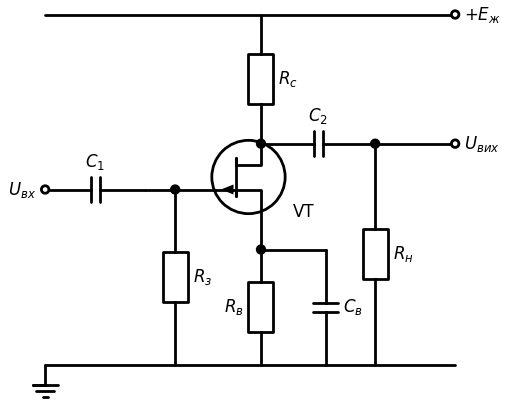

In [6]:
# Каскад СВ з автоматичним зміщенням (ПТ з керувальним p-n переходом і n-каналом)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (8.2, 7)); d += elm.Dot(open=True).at((8.2, 7)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8.2, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 3.5)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 3.5)).to((2, 3.5)).label('$C_1$')
        d += W((2, 3.5), (3.4, 3.5)); d += elm.Dot().at((2.6, 3.5))
        d += elm.Resistor().at((2.6, 3.5)).to((2.6, 0)).label('$R_з$', loc='bottom')
        d += (q := elm.JFetN(circle=True).theta(0).reverse().at((3.4, 3.5)).anchor('gate'))
        d += elm.Label().at((q.source[0] + 0.75, 3.15)).label('VT')
        d += elm.Resistor().at((q.drain[0], 7)).to(q.drain).label('$R_с$', loc='bottom')
        d += W(q.source, (q.source[0], 2.3)); d += elm.Dot().at((q.source[0], 2.3))
        d += elm.Resistor().at((q.source[0], 2.3)).to((q.source[0], 0)).label('$R_в$', loc='top')
        d += W((q.source[0], 2.3), (q.source[0] + 1.3, 2.3)); d += elm.Capacitor().at((q.source[0] + 1.3, 2.3)).to((q.source[0] + 1.3, 0)).label('$C_в$', loc='bottom')
        d += elm.Dot().at(q.drain)
        d += elm.Capacitor().at(q.drain).to((6.6, q.drain[1])).label('$C_2$')
        d += elm.Dot().at((6.6, q.drain[1])); d += W((6.6, q.drain[1]), (8.2, q.drain[1])); d += elm.Dot(open=True).at((8.2, q.drain[1])).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((6.6, q.drain[1])).to((6.6, 0)).label('$R_н$', loc='bottom')

### Параметри каскаду СВ (середні частоти, $C_в$ шунтує $R_в$)

$$K_u = -S\,(R_с\parallel R_н\parallel r_с) \approx -S\,(R_с\parallel R_н),\qquad R_{вх} = R_з,\qquad R_{вих} = R_с\parallel r_с \approx R_с .$$
Без шунтування $R_в$:
$$K_u = -\frac{S\,(R_с\parallel R_н)}{1 + SR_в}.$$

**Порівняння з каскадом СЕ** при однаковому струмі 1 мА: $g_m^{БТ} \approx 38$ мА/В, $S^{ПТ} \approx 1\ldots3$ мА/В — підсилення каскаду СВ у 10…30 разів менше. Зате вхідний опір — мегаоми проти кілоом. Тому каскади на ПТ ставлять першими в підсилювачах сигналів від високоомних джерел (п'єзодатчики, електретні мікрофони, pH-електроди, щупи осцилографів).

---
### 🔬 Інтерактивно: режим спокою і підсилення каскаду СВ (PySpice) <a class="anchor" id="cs-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Модель n-канального ПТ з керувальним переходом: $I_{с.поч} = 4$ мА, $U_{відс} = -2$ В. Ліворуч — передавальна характеристика $I_с(U_{зв})$ і пряма автоматичного зміщення $I_с = -U_{зв}/R_в$; їх перетин — робоча точка. Праворуч — вхідний і вихідний сигнали каскаду. Змінюйте $R_в$ і $R_с$: при великому $R_с$ транзистор виходить з пологої ділянки, і з'являються спотворення.

</div>

In [7]:
# Каскад СВ: графічне визначення робочої точки та часові діаграми (PySpice, модель NJF)
def cs_stage(Rs=680.0, Rd_k=3.3, Uin_mV=100.0):
    Idss, Vp = 4e-3, -2.0
    def build():
        c = Circuit('CS stage')
        c.model('JN', 'NJF', VTO=Vp, BETA=Idss / Vp ** 2, LAMBDA=5e-3, CGS=4e-12, CGD=2e-12)
        c.V('dd', 'vdd', c.gnd, 15)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=Uin_mV * 1e-3, frequency=1e3)
        c.C(1, 'src', 'g', 100e-9); c.R('g', 'g', c.gnd, 1e6)
        c.JFET(1, 'd', 'g', 's', model='JN')
        c.R('d', 'vdd', 'd', Rd_k * 1e3); c.R('s', 's', c.gnd, Rs); c.C('s', 's', c.gnd, 100e-6)
        c.C(2, 'd', 'out', 10e-6); c.R('L', 'out', c.gnd, 1e6)
        return c
    c = build()
    op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
    us = float(np.array(op['s'])[0]); ud = float(np.array(op['d'])[0]); Id = us / Rs
    t, v = tran(c, 2e-6, 6e-3, start=4e-3)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    ugs = np.linspace(Vp, 0, 200)
    a1.plot(ugs, Idss * (1 - ugs / Vp) ** 2 * 1e3, color='#2196F3', label='$I_с(U_{зв})$')
    a1.plot(ugs, -ugs / Rs * 1e3, color='#FF9800', label='пряма зміщення $-U_{зв}/R_в$')
    a1.plot(-us, Id * 1e3, 'o', color='#F44336', label='робоча точка')
    a1.set_ylim(0, Idss * 1e3 * 1.05); a1.set_xlabel('$U_{зв}$, В'); a1.set_ylabel('$I_с$, мА'); a1.legend(fontsize=9)
    a1.set_title(f'$U_{{зв0}}$ = {-us:.2f} В,  $I_{{с0}}$ = {Id*1e3:.2f} мА')
    a2.plot((t - t[0]) * 1e3, v['src'] * 10, 'k--', lw=1, label='$u_{вх}$ × 10')
    a2.plot((t - t[0]) * 1e3, v['out'], color='#F44336', label='$u_{вих}$')
    a2.set_xlabel('t, мс'); a2.set_ylabel('В'); a2.legend(fontsize=9); a2.set_title(f'$U_{{си0}}$ = {ud - us:.2f} В')
    plt.tight_layout(); plt.show()
    S = 2 * np.sqrt(Idss * Id) / abs(Vp)
    Rp = Rd_k * 1e3 * 1e6 / (Rd_k * 1e3 + 1e6)
    print(f'S = {S*1e3:.2f} мА/В;  K_u (формула) = −S·R_с = {-S*Rp:.2f};  K_u (PySpice) ≈ {-(v["out"].max()-v["out"].min())/(2*Uin_mV*1e-3):.2f}')

interact(cs_stage,
         Rs=widgets.FloatSlider(min=100, max=3000, step=20, value=680, description='Rв (Ом)'),
         Rd_k=widgets.FloatSlider(min=0.5, max=10, step=0.1, value=3.3, description='Rс (кОм)'),
         Uin_mV=widgets.FloatSlider(min=10, max=500, step=10, value=100, description='Uвх (мВ)'));

interactive(children=(FloatSlider(value=680.0, description='Rв (Ом)', max=3000.0, min=100.0, step=20.0), Float…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**МДН-транзистор з індукованим каналом не можна змістити автоматично.** Для нього потрібна $U_{зв} > U_{пор} > 0$ (n-канал), а витоковий резистор дає лише від'ємну $U_{зв}$. Автоматичне зміщення працює для ПТ з керувальним p-n переходом і МДН з вбудованим каналом; для індукованого каналу застосовують дільник у колі затвора (часто разом з $R_в$ для стабілізації).

</div>

---

## Каскад зі спільним колектором (емітерний повторювач) <a class="anchor" id="cc-stage"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.15</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати, чому каскад СК називають емітерним повторювачем
> - Розраховувати $K_u$, $R_{вх}$, $R_{вих}$ каскаду СК
> - Пояснювати обмеження вихідної напруги і підвищення вхідного опору («вольтодобавку»)

</div>

У каскаді СК навантаження ввімкнено в коло емітера, колектор з'єднано з джерелом живлення (для змінного сигналу — із загальним проводом). Вихідна напруга знімається з емітера і **повторює** вхідну: $u_{вих} = u_{вх} - u_{бе} \approx u_{вх}$, бо $u_{бе}$ змінюється лише на десятки мілівольт. Каскад **не інвертує** сигнал. Це каскад зі **100 % послідовним НЗЗ за напругою** ($\beta = 1$), тому він має великий вхідний і малий вихідний опір.

**Зміщення і стабілізація** — як у каскаді СЕ: дільник $R_{б1}, R_{б2}$ і резистор $R_е$ (який тут одночасно є навантаженням за постійним струмом). Оскільки весь сигнал і вся напруга $I_еR_е$ діють як НЗЗ, стабільність робочої точки висока. Напругу бази вибирають $\approx E_ж/2$ для симетричного розмаху.

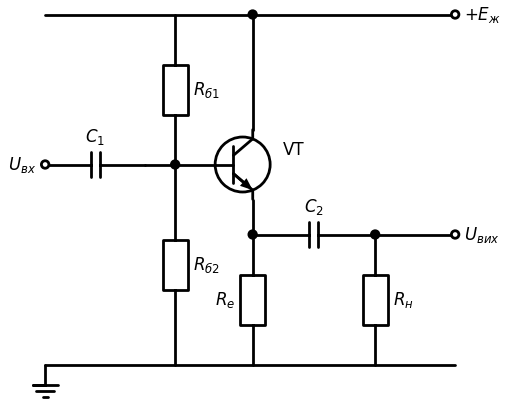

In [8]:
# Каскад СК (емітерний повторювач)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (8.2, 7)); d += elm.Dot(open=True).at((8.2, 7)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8.2, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 4)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 4)).to((2, 4)).label('$C_1$')
        d += W((2, 4), (3.4, 4)); d += elm.Dot().at((2.6, 4))
        d += elm.Resistor().at((2.6, 7)).to((2.6, 4)).label('$R_{б1}$', loc='bottom')
        d += elm.Resistor().at((2.6, 4)).to((2.6, 0)).label('$R_{б2}$', loc='bottom')
        d += elm.BjtNpn(circle=True).theta(0).at((3.4, 4)).anchor('base').label('VT', loc='right', ofst=(0.25, 0.3))
        d += W((4.15, 4.7), (4.15, 7)); d += elm.Dot().at((4.15, 7))
        d += W((4.15, 3.3), (4.15, 2.6)); d += elm.Dot().at((4.15, 2.6))
        d += elm.Resistor().at((4.15, 2.6)).to((4.15, 0)).label('$R_е$', loc='top')
        d += elm.Capacitor().at((4.15, 2.6)).to((6.6, 2.6)).label('$C_2$')
        d += elm.Dot().at((6.6, 2.6)); d += W((6.6, 2.6), (8.2, 2.6)); d += elm.Dot(open=True).at((8.2, 2.6)).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((6.6, 2.6)).to((6.6, 0)).label('$R_н$', loc='bottom')

### Параметри каскаду СК

Позначимо $R'_е = R_е\parallel R_н$, $R'_c = R_c\parallel R_б$ — опір джерела сигналу з урахуванням дільника.
$$K_u = \frac{(1+\beta)R'_е}{h_{11е} + (1+\beta)R'_е} \approx \frac{R'_е}{r_е + R'_е} \lesssim 1,$$
$$R_{вх} = R_б\parallel\left[h_{11е} + (1+\beta)R'_е\right],\qquad R_{вих} = R_е\parallel\frac{h_{11е} + R'_c}{1+\beta} \approx r_е + \frac{R'_c}{\beta},\qquad K_i \approx 1+\beta .$$
Отже, повторювач **трансформує опори**: опір навантаження «видно» з входу збільшеним у $(1+\beta)$ разів, а опір джерела з виходу — зменшеним у $(1+\beta)$ разів. Тому повторювач використовують як **буферний (узгоджувальний) каскад** між високоомним джерелом і низькоомним навантаженням.

**Обмеження:**
- вхідний опір обмежений дільником $R_б$ (кілька десятків кОм). Для його підвищення застосовують **«вольтодобавку» (bootstrap)**: резистор у колі бази живлять від виходу через конденсатор, тож змінна напруга на ньому майже нульова і його опір для сигналу зростає в $1/(1-K_u)$ разів;
- при низькоомному навантаженні і великому сигналі транзистор закривається на від'ємній півхвилі: від'ємна амплітуда обмежена значенням $U_{max}^- \approx I_{е0}\,(R_е\parallel R_н)$ — потрібен достатній струм спокою (або двотактний повторювач чи джерело струму замість $R_е$).

---
### 🔬 Інтерактивно: емітерний повторювач: обмеження від'ємної півхвилі (PySpice) <a class="anchor" id="cc-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Повторювач на 2N3904 ($E_ж = 12$ В, $R_е = 2{,}2$ кОм, струм спокою ≈ 2,4 мА) з навантаженням $R_н$ через розділювальний конденсатор. Зменшуйте $R_н$ і збільшуйте амплітуду: від'ємна півхвиля обмежується на рівні $I_{е0}(R_е\parallel R_н)$, бо транзистор закривається, а розряджати $C_2$ може лише $R_е$.

</div>

In [9]:
# Емітерний повторювач: часові діаграми, коефіцієнт передачі, обмеження
def cc_stage(Rl=1000.0, Uin=2.0):
    c = Circuit('CC stage')
    c.include(spice_model('2n3904.lib'))
    c.V('cc', 'vcc', c.gnd, 12)
    c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=Uin, frequency=1e3)
    c.C(1, 'src', 'b', 10e-6); c.R('b1', 'vcc', 'b', 33e3); c.R('b2', 'b', c.gnd, 33e3)
    c.BJT(1, 'vcc', 'b', 'e', model='Q2N3904')
    c.R('e', 'e', c.gnd, 2.2e3)
    c.C(2, 'e', 'out', 100e-6); c.R('L', 'out', c.gnd, Rl)
    op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
    ie = float(np.array(op['e'])[0]) / 2.2e3
    t, v = tran(c, 2e-6, 0.4, start=0.396)
    fig, ax = plt.subplots(figsize=(9, 4))
    tt = (t - t[0]) * 1e3
    ax.plot(tt, v['src'], 'k--', lw=1, label='$u_{вх}$'); ax.plot(tt, v['out'], color='#F44336', label='$u_{вих}$')
    lim = ie * 2.2e3 * Rl / (2.2e3 + Rl)
    ax.axhline(-lim, color='#FF9800', ls=':', label=f'$-I_{{е0}}(R_е\\parallel R_н)$ = {-lim:.2f} В')
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)
    ax.set_title(f'Повторювач: $R_н$ = {Rl:.0f} Ом, $I_{{е0}}$ = {ie*1e3:.2f} мА')
    plt.tight_layout(); plt.show()
    print(f'Розмах виходу: +{v["out"].max():.2f} / {v["out"].min():.2f} В;  K_u (додатна півхвиля) = {v["out"].max()/Uin:.3f}')

interact(cc_stage,
         Rl=widgets.FloatLogSlider(base=10, min=2, max=5, step=0.1, value=1000, description='Rн (Ом)'),
         Uin=widgets.FloatSlider(min=0.2, max=5, step=0.1, value=2, description='Uвх (В)'));

interactive(children=(FloatLogSlider(value=1000.0, description='Rн (Ом)', max=5.0, min=2.0), FloatSlider(value…

---
### ⚡ Практичне застосування: порівняння основних каскадів

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Параметр | СЕ | СВ | СК (повторювач) |
|---|---|---|---|
| $K_u$ | $-g_m(R_к\parallel R_н)$, десятки–сотні | $-S(R_с\parallel R_н)$, одиниці–десятки | $\lesssim 1$ |
| $K_i$ | $\approx\beta$ | дуже великий | $\approx 1+\beta$ |
| $R_{вх}$ | $R_б\parallel h_{11е}$, ~1…5 кОм | $R_з$, ~1 МОм | $R_б\parallel(1+\beta)R'_е$, десятки кОм |
| $R_{вих}$ | $\approx R_к$, кілооми | $\approx R_с$, кілооми | $r_е + R'_c/\beta$, одиниці–десятки Ом |
| Фаза | $180°$ | $180°$ | $0°$ |
| Застосування | основний підсилювальний каскад | вхідний каскад для високоомних джерел | буфер, вихідний каскад, узгодження |

</div>

---
### ✅ Питання для самоперевірки: каскади СЕ, СВ, СК

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Навіщо в каскаді СЕ конденсатор $C_е$?</summary>

> **Відповідь:** Він шунтує $R_е$ на робочих частотах: НЗЗ через $R_е$ діє лише за постійним струмом (стабілізує режим), а змінний сигнал підсилюється з повним $K_u = -g_m(R_к\parallel R_н)$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому схема з фіксованим струмом бази нестабільна?</summary>

> **Відповідь:** Струм колектора $I_к = \beta I_б$ прямо пропорційний $\beta$, яке має великий розкид і зростає з температурою; НЗЗ, який би компенсував зміни, відсутній ($S = 1+\beta$).

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Як працює автоматичне зміщення ПТ?</summary>

> **Відповідь:** Струм стоку створює на $R_в$ падіння напруги; затвор через $R_з$ має потенціал землі, тому $U_{зв} = -I_сR_в$ — від'ємне зміщення без окремого джерела. Одночасно $R_в$ стабілізує струм (НЗЗ).

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чому каскад СК має малий вихідний опір?</summary>

> **Відповідь:** Це 100 % НЗЗ за напругою: будь-яка зміна вихідної напруги повністю передається на перехід база–емітер і компенсується; опір джерела «видно» з виходу зменшеним у $(1+\beta)$ разів.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому каскад СВ має менше підсилення, ніж СЕ?</summary>

> **Відповідь:** Крутизна ПТ при тому самому струмі значно менша за крутизну БТ $g_m = I_к/\varphi_т$.

</details>

---
### 📝 Задачі для самостійного розв'язання: каскади СЕ, СВ, СК


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Каскад СЕ: $E_ж = 12$ В, $R_{б1} = 47$ кОм, $R_{б2} = 10$ кОм, $R_е = 1$ кОм (зашунтовано), $R_к = 4{,}7$ кОм, $R_н = 10$ кОм, $\beta = 200$. Знайдіть $I_{к0}$, $U_{ке0}$, $g_m$, $K_u$, $R_{вх}$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $U_{б0} = 2{,}11$ В, $R_б = 8{,}25$ кОм; $I_{е0} = (2{,}11 - 0{,}65)/(1 + 8{,}25/201) \approx 1{,}40$ мА; $U_{ке0} \approx 12 - 1{,}4\cdot5{,}7 = 4{,}0$ В; $g_m = 54$ мА/В; $K_u = -54\cdot3{,}2 \approx -173$; $h_{11е} = 200/54 \approx 3{,}7$ кОм; $R_{вх} = 8{,}25\parallel3{,}7 \approx 2{,}6$ кОм.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** ПТ з $I_{с.поч} = 6$ мА, $U_{відс} = -3$ В у схемі з автоматичним зміщенням має працювати при $I_{с0} = 1{,}5$ мА. Знайдіть $R_в$, крутизну і $K_u$ при $R_с = 4{,}7$ кОм.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $U_{зв} = U_{відс}(1 - \sqrt{I_с/I_{с.поч}}) = -3(1 - 0{,}5) = -1{,}5$ В; $R_в = 1$ кОм; $S = 2\sqrt{6\cdot1{,}5}/3 = 2$ мА/В; $K_u = -9{,}4$.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Повторювач: $\beta = 100$, $I_{е0} = 5$ мА, $R_е = 1$ кОм, $R_н = 1$ кОм, опір джерела з дільником $R\'_c = 10$ кОм. Знайдіть $K_u$, $R_{вх.тр}$ і $R_{вих}$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $r_е = 5{,}2$ Ом; $R\'_е = 500$ Ом; $K_u = 500/505 = 0{,}99$; $R_{вх.тр} \approx 101\cdot505 \approx 51$ кОм; $R_{вих} \approx 5{,}2 + 10000/101 \approx 104$ Ом.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Каскад | $K_u$ | $R_{вх}$ | $R_{вих}$ |
|---|---|---|---|
| СЕ | $-g_m(R_к\parallel R_н)$; з $R_е$: $-\dfrac{R_к\parallel R_н}{R_е}$ | $R_б\parallel h_{11е}$ | $\approx R_к$ |
| СВ | $-S(R_с\parallel R_н)$ | $R_з$ | $\approx R_с$ |
| СК | $\dfrac{R'_е}{r_е + R'_е}\approx 1$ | $R_б\parallel(1+\beta)R'_е$ | $r_е + R'_c/\beta$ |

Режим спокою: $I_{е0} \approx (U_{б0} - 0{,}65)/R_е$; коефіцієнт нестабільності $S \approx 1 + R_б/R_е$ (емітерна стабілізація), $S = 1+\beta$ (фіксований струм бази).

**Головні висновки.** Каскад СЕ — основний підсилювач напруги і струму; СВ — підсилювач з дуже великим вхідним опором; СК — повторювач-буфер з малим вихідним опором. Стабільність робочої точки забезпечується місцевим НЗЗ за постійним струмом (резистори $R_е$, $R_в$), а на робочих частотах цей НЗЗ за потреби вимикають шунтувальними конденсаторами.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Степаненко И. П. Основы микроэлектроники. — М.: Лаборатория Базовых Знаний, 2001.
7. Razavi B. Fundamentals of Microelectronics. — 2nd ed. — Wiley, 2014.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 2. Багатокаскадні підсилювачі. Зворотний зв'язок і стійкість](Тема_02_Багатокаскадні_підсилювачі_та_зворотний_звязок.ipynb) &nbsp;|&nbsp; [Тема 4. Каскади СС, СБ, СЗ. Корекція АЧХ](Тема_04_Каскади_СС_СБ_СЗ_та_корекція_АЧХ.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*